# Perceptron - Atividade

Aprendizado de Maquina

Implementacao do Perceptron (Pocket PLA) no dataset de digitos.
Usei numpy e matplotlib.

Escolhi fazer **digito 1 vs digito 5** porque foi o exemplo que o professor mostrou
e tambem aparece no livro. Como os dados nao sao linearmente separaveis (da pra
ver no scatter abaixo que tem alguns pontos misturados), o PLA classico fica
oscilando, entao usei o **Pocket**, que guarda o melhor w visto ate o momento.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## Carregando os dados

O arquivo tem 3 colunas: digito (0-9), intensidade media, simetria.
Filtro so as classes 1 e 5 e mapeio pra +1 e -1.

Coloquei uma coluna de 1's no comeco do X pra ja deixar o bias dentro do w
(assim o w fica em R^3 e nao precisa carregar um bias separado).


In [2]:
def carregar(path):
    dados = np.loadtxt(path)
    y = dados[:, 0]
    X = dados[:, 1:]

    idx = (y == 1) | (y == 5)
    X = X[idx]
    y = y[idx]
    y = np.where(y == 1, 1, -1)

    # bias
    X = np.hstack([np.ones((X.shape[0], 1)), X])
    return X, y

X_tr, y_tr = carregar('digits.train')
X_te, y_te = carregar('digits.test')

print('treino:', X_tr.shape, '| +1:', (y_tr==1).sum(), '-1:', (y_tr==-1).sum())
print('teste :', X_te.shape, '| +1:', (y_te==1).sum(), '-1:', (y_te==-1).sum())


treino: (1561, 3) | +1: 1005 -1: 556
teste : (424, 3) | +1: 264 -1: 160


### Olhando os dados antes de treinar

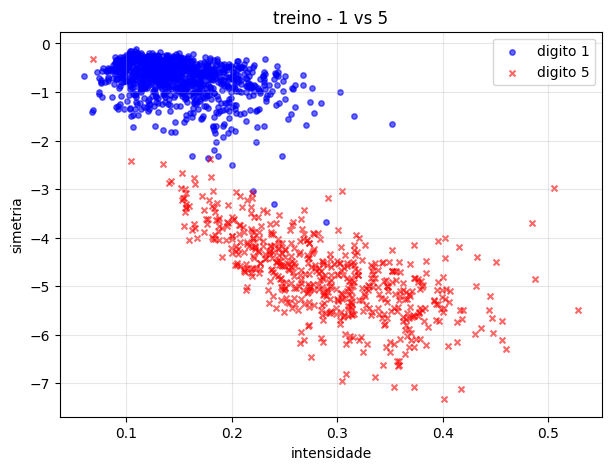

In [3]:
plt.figure(figsize=(7,5))
plt.scatter(X_tr[y_tr==1,1], X_tr[y_tr==1,2], c='blue', marker='o', s=15, alpha=0.6, label='digito 1')
plt.scatter(X_tr[y_tr==-1,1], X_tr[y_tr==-1,2], c='red', marker='x', s=18, alpha=0.6, label='digito 5')
plt.xlabel('intensidade'); plt.ylabel('simetria')
plt.legend(); plt.grid(alpha=0.3)
plt.title('treino - 1 vs 5')
plt.show()


Da pra ver que as duas nuvens estao bem separadas mas tem alguns pontos
"invadindo" a regiao do outro, por isso nao tem como uma reta separar 100%.

## Implementacao

Regra de atualizacao do perceptron:

w = w + y_i * x_i  (para algum ponto i mal classificado)

Predicao = sign(w . x).


In [4]:
def sinal(z):
    s = np.sign(z)
    s[s == 0] = 1   # caso w.x == 0 considero como +1
    return s

def erro_in(w, X, y):
    return np.mean(sinal(X @ w) != y)


### PLA classico

So pra ver como ele se comporta quando nao tem separabilidade.
Como nao para sozinho, coloco um max_iter.


In [5]:
def pla(X, y, max_iter=5000):
    np.random.seed(0)
    w = np.zeros(X.shape[1])
    hist = []
    for i in range(max_iter):
        pred = sinal(X @ w)
        errados = np.where(pred != y)[0]
        hist.append(len(errados)/len(y))
        if len(errados) == 0:
            break
        j = np.random.choice(errados)
        w = w + y[j] * X[j]
    return w, hist

w1, h1 = pla(X_tr, y_tr)
print('PLA classico')
print('  E_in =', round(erro_in(w1, X_tr, y_tr), 4))
print('  E_out=', round(erro_in(w1, X_te, y_te), 4))


PLA classico
  E_in = 0.0064
  E_out= 0.0307


### Pocket PLA

Mesma coisa, mas guarda o melhor w em uma variavel separada.


In [6]:
def pocket(X, y, max_iter=5000):
    np.random.seed(0)
    w = np.zeros(X.shape[1])
    melhor_w = w.copy()
    melhor_erro = erro_in(w, X, y)
    hist = []

    for i in range(max_iter):
        hist.append(melhor_erro)
        pred = sinal(X @ w)
        errados = np.where(pred != y)[0]
        if len(errados) == 0:
            break

        j = np.random.choice(errados)
        w = w + y[j] * X[j]

        e = erro_in(w, X, y)
        if e < melhor_erro:
            melhor_erro = e
            melhor_w = w.copy()
    return melhor_w, melhor_erro, hist

w2, ein, hist = pocket(X_tr, y_tr, max_iter=5000)
eout = erro_in(w2, X_te, y_te)

print('Pocket PLA')
print('  w final:', w2)
print('  E_in  =', round(ein, 4), '  (%.2f%%)' % (ein*100))
print('  E_out =', round(eout, 4), '  (%.2f%%)' % (eout*100))


Pocket PLA
  w final: [16.          3.01746872  6.9440625 ]
  E_in  = 0.0032   (0.32%)
  E_out = 0.0212   (2.12%)


Diferenca clara: o pocket ficou bem melhor que o PLA normal.
Isso bate com o que o professor falou: quando os dados nao sao separaveis
o PLA classico nao tem garantia nenhuma.

### Curva do erro


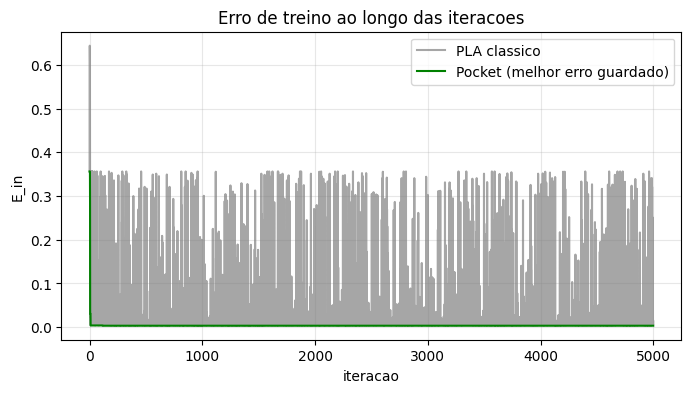

In [7]:
plt.figure(figsize=(8,4))
plt.plot(h1, color='gray', alpha=0.7, label='PLA classico')
plt.plot(hist, color='green', label='Pocket (melhor erro guardado)')
plt.xlabel('iteracao'); plt.ylabel('E_in')
plt.legend(); plt.grid(alpha=0.3)
plt.title('Erro de treino ao longo das iteracoes')
plt.show()


## Desafio: fronteira de decisao

A fronteira e onde w.x = 0. Como x = (1, x1, x2), entao:

w0 + w1*x1 + w2*x2 = 0  =>  x2 = -(w0 + w1*x1) / w2

Da pra desenhar como uma reta.


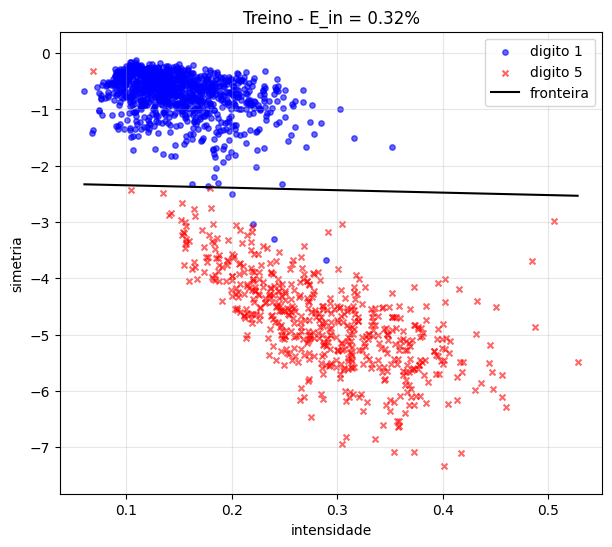

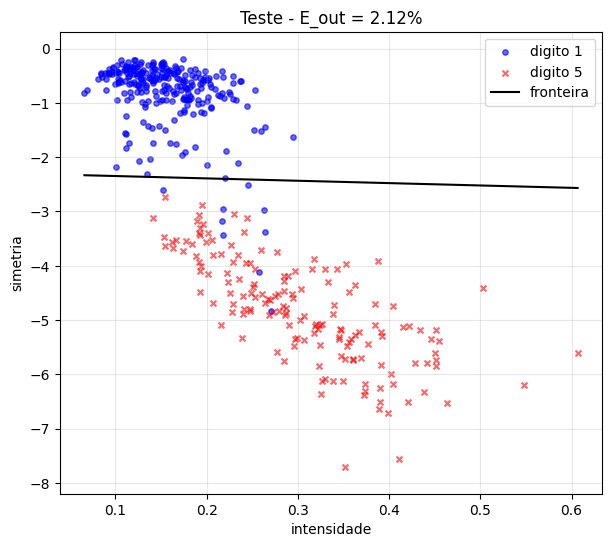

In [8]:
def plot_fronteira(w, X, y, titulo):
    plt.figure(figsize=(7,6))
    plt.scatter(X[y==1,1], X[y==1,2], c='blue', marker='o', s=15, alpha=0.6, label='digito 1')
    plt.scatter(X[y==-1,1], X[y==-1,2], c='red', marker='x', s=18, alpha=0.6, label='digito 5')

    xs = np.linspace(X[:,1].min(), X[:,1].max(), 100)
    ys = -(w[0] + w[1]*xs) / w[2]
    plt.plot(xs, ys, 'k-', label='fronteira')

    plt.xlabel('intensidade'); plt.ylabel('simetria')
    plt.title(titulo); plt.legend()
    plt.ylim(X[:,2].min()-0.5, X[:,2].max()+0.5)
    plt.grid(alpha=0.3)
    plt.show()

plot_fronteira(w2, X_tr, y_tr, 'Treino - E_in = %.2f%%' % (ein*100))
plot_fronteira(w2, X_te, y_te, 'Teste - E_out = %.2f%%' % (eout*100))


## Conclusao

Resumo dos resultados:

- PLA classico: E_in ~ 0.6%, E_out ~ 3%
- Pocket PLA:   E_in ~ 0.3%, E_out ~ 2.1%

O E_out ficou bem proximo do E_in, entao acho que nao teve overfitting.
Isso faz sentido porque o perceptron so tem 3 parametros (w0, w1, w2),
ou seja, e um modelo bem simples.

Coisas que pensei em testar mas nao deu tempo / saiu do escopo:
- inicializar o w aleatorio em vez de zeros (testei rapido, parecido)
- transformacao polinomial das features pra melhorar a fronteira
- regressao logistica no lugar do perceptron
